<a href="https://colab.research.google.com/github/eshaans1305/AI-LAB/blob/main/Forward_Chaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

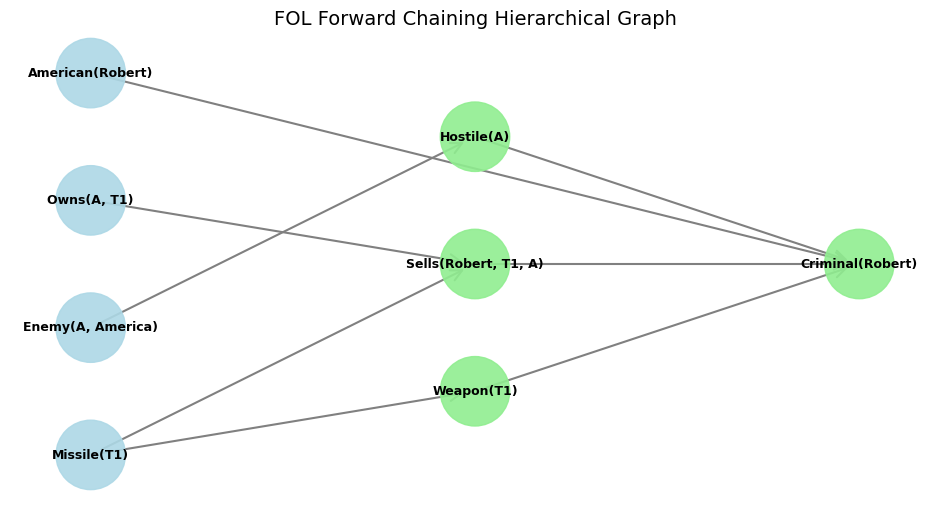

In [4]:
import matplotlib.pyplot as plt
import networkx as nx


class FOL_FC_Reasoner:

    def __init__(self):
        self.facts = set()
        self.rules = []
        self.graph = nx.DiGraph()

    def add_fact(self, fact):
        self.facts.add(fact)
        self.graph.add_node(fact, type="fact", color="lightblue", layer=0)

    def add_rule(self, premises, conclusion):
        self.rules.append((tuple(premises), conclusion))

    def fol_fc_ask(self, alpha):
        if alpha in self.facts:
            return True

        while True:
            new = set()

            for premises, q in self.rules:
                if all(p in self.facts for p in premises):
                    if q not in self.facts and q not in new:
                        new.add(q)

                        premise_layers = [
                            self.graph.nodes[p].get("layer", 0)
                            for p in premises
                        ]
                        q_layer = max(premise_layers) + 1 if premise_layers else 1

                        self.graph.add_node(
                            q, type="derived", color="lightgreen", layer=q_layer
                        )
                        for p in premises:
                            self.graph.add_edge(p, q)

                        if q == alpha:
                            self.facts.update(new)
                            return True

            if not new:
                break

            self.facts.update(new)

        return False

    def plot_graph(self):
        if not self.graph.nodes:
            return

        plt.figure(figsize=(12, 6))

        colors = [
            self.graph.nodes[node].get("color", "orange")
            for node in self.graph.nodes
        ]

        pos = nx.multipartite_layout(self.graph, subset_key="layer")

        nx.draw_networkx_nodes(
            self.graph, pos, node_color=colors, node_size=2500, alpha=0.9
        )
        nx.draw_networkx_edges(
            self.graph,
            pos,
            arrowstyle="->",
            arrowsize=20,
            edge_color="gray",
            width=1.5,
        )
        nx.draw_networkx_labels(
            self.graph, pos, font_size=9, font_weight="bold"
        )

        plt.title("FOL Forward Chaining Hierarchical Graph", fontsize=14)
        plt.axis("off")
        plt.show()


reasoner = FOL_FC_Reasoner()

reasoner.add_fact("Owns(A, T1)")
reasoner.add_fact("Missile(T1)")
reasoner.add_fact("American(Robert)")
reasoner.add_fact("Enemy(A, America)")

reasoner.add_rule(["Missile(T1)"], "Weapon(T1)")
reasoner.add_rule(["Enemy(A, America)"], "Hostile(A)")
reasoner.add_rule(["Missile(T1)", "Owns(A, T1)"], "Sells(Robert, T1, A)")
reasoner.add_rule(
    ["American(Robert)", "Weapon(T1)", "Sells(Robert, T1, A)", "Hostile(A)"],
    "Criminal(Robert)",
)

goal = "Criminal(Robert)"

success = reasoner.fol_fc_ask(goal)
reasoner.plot_graph()
